In [4]:
# === CELLULE 2 : Imports ===
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import stable_baselines3 as sb3
from stable_baselines3 import PPO, A2C, DQN
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.results_plotter import load_results, ts2xy

print("gymnasium :", gym.__version__)
print("SB3       :", sb3.__version__)
print("numpy     :", np.__version__)

sns.set_theme(style="whitegrid")

I0000 00:00:1795541087.389881  149837 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


gymnasium : 1.4.0
SB3       : 2.9.2
numpy     : 2.5.3


In [5]:
# === CELLULE 3 : Découverte de l'environnement (MDP) ===
env = gym.make("CartPole-v1")
obs, info = env.reset(seed=42)

print("Espace d'observation :", env.observation_space)
print("  -> 4 dimensions : [x, ẋ, θ, θ̇]")
print("Espace d'action      :", env.action_space)
print("  -> Discrete(2) : 0 = pousser à gauche, 1 = pousser à droite")
print("Observation initiale :", obs)
print("Info                 :", info)

# Un pas aléatoire
action = env.action_space.sample()
obs, reward, terminated, truncated, info = env.step(action)
print(f"\nAction={action}, obs={obs}, reward={reward}, "
      f"terminated={terminated}, truncated={truncated}")
env.close()

Espace d'observation : Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
  -> 4 dimensions : [x, ẋ, θ, θ̇]
Espace d'action      : Discrete(2)
  -> Discrete(2) : 0 = pousser à gauche, 1 = pousser à droite
Observation initiale : [ 0.0273956  -0.00611216  0.03585979  0.0197368 ]
Info                 : {}

Action=1, obs=[ 0.02727336  0.18847767  0.03625453 -0.26141977], reward=1.0, terminated=False, truncated=False


In [6]:
# === CELLULE 4 : Exemple 1 — PPO + test d'un épisode ===
env = gym.make("CartPole-v1", render_mode=None)   # pas de rendu en notebook
env = Monitor(env, filename="logs/ex1/")

model = PPO("MlpPolicy", env, verbose=1, seed=0)
model.learn(total_timesteps=10_000)
print("Entraînement terminé !")

# Test sur 1 épisode
obs, info = env.reset()
done, total_reward = False, 0
while not done:
    action, _ = model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated
    total_reward += reward
env.close()
print(f"Récompense totale de l'épisode : {total_reward}")

Using cpu device
Wrapping the env in a DummyVecEnv.
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 25.7     |
|    ep_rew_mean     | 25.7     |
| time/              |          |
|    fps             | 1001     |
|    iterations      | 1        |
|    time_elapsed    | 2        |
|    total_timesteps | 2048     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 29.9        |
|    ep_rew_mean          | 29.9        |
| time/                   |             |
|    fps                  | 761         |
|    iterations           | 2           |
|    time_elapsed         | 5           |
|    total_timesteps      | 4096        |
| train/                  |             |
|    approx_kl            | 0.007937547 |
|    clip_fraction        | 0.0963      |
|    clip_range           | 0.2         |
|    entropy_loss         | -0.686      |
|    explained_varia

Épisode 1 - Récompense : 500.0
Épisode 2 - Récompense : 500.0
Épisode 3 - Récompense : 325.0
Épisode 4 - Récompense : 500.0
Épisode 5 - Récompense : 344.0


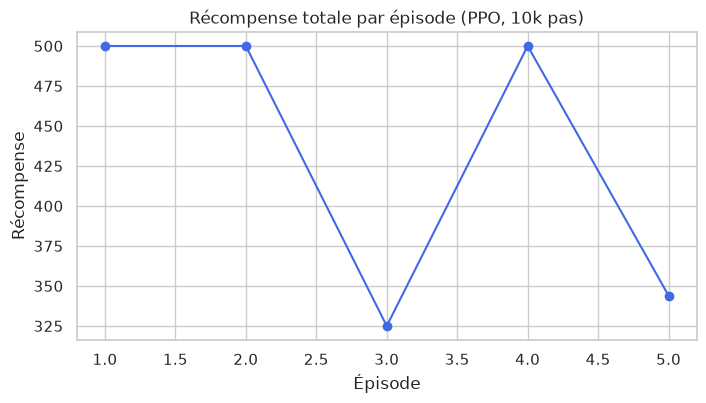

Moyenne = 433.8 | Écart-type = 81.30


In [7]:
# === CELLULE 5 : Exemple 2 — PPO + statistiques sur 5 épisodes ===
env = gym.make("CartPole-v1", render_mode=None)
env = Monitor(env, filename="logs/ex2/")

model = PPO("MlpPolicy", env, verbose=0, seed=0)
model.learn(total_timesteps=10_000)

num_episodes = 5
rewards_list = []
for ep in range(num_episodes):
    obs, info = env.reset()
    done, total_reward = False, 0
    while not done:
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        total_reward += reward
    rewards_list.append(total_reward)
    print(f"Épisode {ep+1} - Récompense : {total_reward}")
env.close()

plt.figure(figsize=(8,4))
plt.plot(range(1, num_episodes+1), rewards_list, marker='o', color='royalblue')
plt.title("Récompense totale par épisode (PPO, 10k pas)")
plt.xlabel("Épisode"); plt.ylabel("Récompense")
plt.grid(True); plt.show()

print(f"Moyenne = {np.mean(rewards_list):.1f} | Écart-type = {np.std(rewards_list):.2f}")

Évaluation sur 20 épisodes : 500.0 ± 0.0


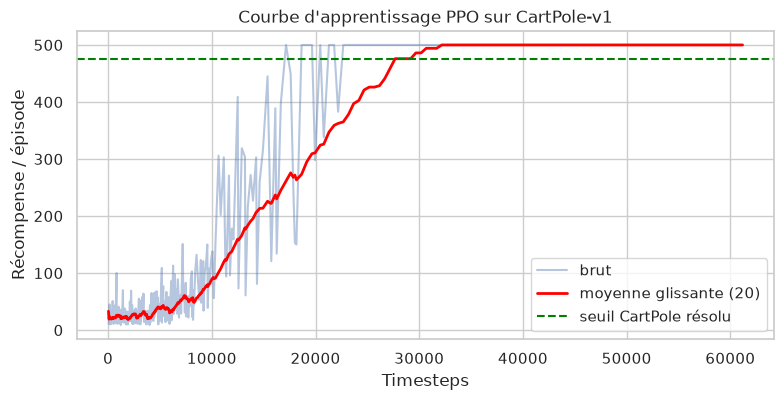

In [8]:
# === CELLULE 7 : Évaluation robuste et courbe d'apprentissage ===
import os
os.makedirs("logs/eval", exist_ok=True)

env = Monitor(gym.make("CartPole-v1"), filename="logs/eval/")
model = PPO("MlpPolicy", env, verbose=0, seed=42,
            learning_rate=3e-4, n_steps=2048, gamma=0.99)
model.learn(total_timesteps=50_000)

mean_r, std_r = evaluate_policy(model, env, n_eval_episodes=20,
                                deterministic=True, return_episode_rewards=False)
print(f"Évaluation sur 20 épisodes : {mean_r:.1f} ± {std_r:.1f}")

# Courbe d'apprentissage
x, y = ts2xy(load_results("logs/eval"), "timesteps")
if len(x) > 0:
    plt.figure(figsize=(9,4))
    plt.plot(x, y, alpha=0.4, label="brut")
    plt.plot(x, pd.Series(y).rolling(20, min_periods=1).mean(),
             color="red", lw=2, label="moyenne glissante (20)")
    plt.axhline(475, ls="--", color="green", label="seuil CartPole résolu")
    plt.xlabel("Timesteps"); plt.ylabel("Récompense / épisode")
    plt.title("Courbe d'apprentissage PPO sur CartPole-v1")
    plt.legend(); plt.grid(True); plt.show()